# 🎨 Notebook 3 — Copolymers & Chemical Composition
| | |
|---|---|
| ⏱ Time | ~40 min |
| 🧭 Type | **steady state Monte Carlo** (book Ch. 3) |
| 🎯 You will learn | track *what* is in each chain · chemical composition distribution (CCD) · Bernoulli vs. terminal model · bivariate (length × composition) maps |
| 🧰 Uses | Notebook 2's chain-growth loop, plus a second `Rnd` to pick the monomer |
| 📖 Book | Sec. 3.2 (Case Study 3.2 is reproduced in full in Notebook 9) |

Two monomers: **M1 = styrene** and **M2 = methyl methacrylate (MMA)**. Each chain now carries two numbers: its length `n` and its number of M1 units `n1`. Theory: *Monte Carlo Methods in Polymer Reaction Engineering: From Mechanisms to Molecular Architecture*.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LogNorm

random.seed(7)

## 1 · Bernoulli model: every unit is a coin flip
Same growth loop as before, plus one extra question at each step: **is the new unit M1?** (`Rnd ≤ f1`, where `f1` is the fraction of M1 in the monomer feed).

In [2]:
def grow_bernoulli(Pp, f1):
    n = 1
    n1 = 0
    if random.random() <= f1:          # is the first unit M1?
        n1 = 1
    while random.random() <= Pp:       # propagate?
        n += 1
        if random.random() <= f1:      # which monomer?
            n1 += 1
    return n, n1

In [3]:
for i in range(5):
    n, n1 = grow_bernoulli(0.99, 0.5)
    print(f"length {n:4d}   styrene units {n1:4d}   F1 = {n1 / n:.3f}")

length   37   styrene units   18   F1 = 0.486
length   35   styrene units   23   F1 = 0.657
length  232   styrene units  122   F1 = 0.526
length   63   styrene units   33   F1 = 0.524
length   56   styrene units   28   F1 = 0.500


`F1 = n1/n` is the **mole fraction of M1 in that chain**. Let's make many chains and keep both numbers in two lists, `D` and `N1` (the book's convention for copolymers: entry `k` belongs to chain `k`).

In [4]:
def run_bernoulli(N, Pp, f1):
    D = []
    N1 = []
    for k in range(N):
        n, n1 = grow_bernoulli(Pp, f1)
        D.append(n)
        N1.append(n1)
    return np.array(D), np.array(N1)

## 2 · The chemical composition distribution (CCD)
Book Algorithm 3.4, in three steps:
1. composition of every chain: `F1 = N1 / D`
2. sort the chains into composition bins of width `ΔF1`, adding up their **lengths** (= mass)
3. normalize

`np.histogram(..., weights=D)` does step 2 in one call: it adds `D[k]` to the bin that `F1[k]` falls in.

In [5]:
def ccd(D, N1, dF=0.04):
    F1 = N1 / D
    edges = np.arange(0, 1 + dF, dF)
    Y, edges = np.histogram(F1, bins=edges, weights=D)
    centers = (edges[1:] + edges[:-1]) / 2
    return centers, Y / Y.sum() / dF

Short chains have few units, so their composition scatters a lot (few coin flips). Long chains average out. Compare three chain lengths:

In [6]:
ccd_results = {}
for Pp in [0.9, 0.99, 0.999]:
    D, N1 = run_bernoulli(20_000, Pp, 0.5)
    ccd_results[Pp] = ccd(D, N1)

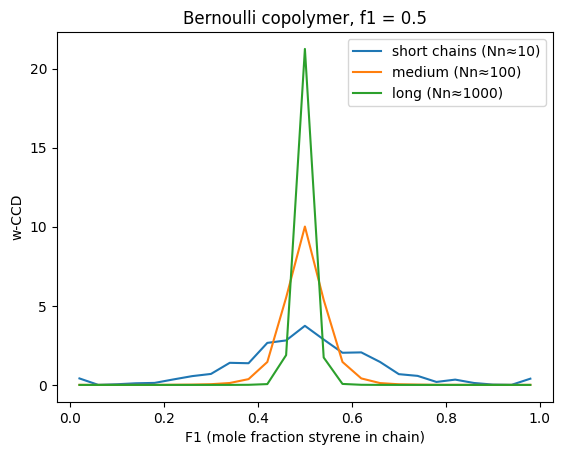

In [7]:
#@title Plot the CCDs
labels = {0.9: "short chains (Nn≈10)", 0.99: "medium (Nn≈100)", 0.999: "long (Nn≈1000)"}
for Pp in ccd_results:
    F, c = ccd_results[Pp]; plt.plot(F, c, label=labels[Pp])
plt.xlabel("F1 (mole fraction styrene in chain)"); plt.ylabel("w-CCD")
plt.title("Bernoulli copolymer, f1 = 0.5"); plt.legend(); plt.show()

## 3 · Terminal model: the chain *remembers* its last unit
In real copolymerization, the chance of adding M1 depends on the radical's **last unit**. With reactivity ratios `r1`, `r2` and feed fractions `f1`, `f2 = 1 − f1`:

| last unit | probability of adding M1 |
|---|---|
| M1 (radical P) | `P_p,11 = r1·f1 / (r1·f1 + f2)` |
| M2 (radical Q) | `P_p,21 = f1 / (f1 + r2·f2)` |

In [8]:
def prob_add_M1(f1, r1, r2):
    f2 = 1 - f1
    P11 = r1 * f1 / (r1 * f1 + f2)     # last unit M1
    P21 = f1 / (f1 + r2 * f2)          # last unit M2
    return {1: P11, 2: P21}

The result is a dictionary keyed by the last unit, so `Padd1[last]` is always the right probability. The growth loop now tracks `last`:

In [9]:
def grow_terminal(last, Pp, Padd1):
    n = 1
    n1 = 0
    if last == 1:
        n1 = 1
    while random.random() <= Pp:
        n += 1
        if random.random() <= Padd1[last]:
            last = 1
            n1 += 1
        else:
            last = 2
    return n, n1, last

A new chain starts with M1 with probability `f1`:

In [10]:
def first_unit(f1):
    if random.random() <= f1:
        return 1
    return 2

Now the full model, with termination by **combination** (probability `Ptc`, here 0.9 for P radicals and 0.3 for Q radicals) or **transfer**:

In [11]:
def run_terminal(N, f1, r1, r2, Pp, Ptc):
    Padd1 = prob_add_M1(f1, r1, r2)
    D, N1 = [], []
    for k in range(N):
        n, n1, last = grow_terminal(first_unit(f1), Pp, Padd1)
        if random.random() <= Ptc[last]:                  # combination
            m, m1, l2 = grow_terminal(first_unit(f1), Pp, Padd1)
            n, n1 = n + m, n1 + m1
        D.append(n)
        N1.append(n1)
    return np.array(D), np.array(N1)

### ✅ Validation: the Mayo–Lewis equation
The average copolymer composition must follow the classic Mayo–Lewis equation. Simulate several feed compositions for styrene/MMA (`r1 = 0.52`, `r2 = 0.46`):

In [12]:
r1, r2 = 0.52, 0.46
Ptc = {1: 0.9, 2: 0.3}
f_values = np.linspace(0.05, 0.95, 10)

F_mc = []
for f1 in f_values:
    D, N1 = run_terminal(3000, f1, r1, r2, 0.995, Ptc)
    F_mc.append(N1.sum() / D.sum())

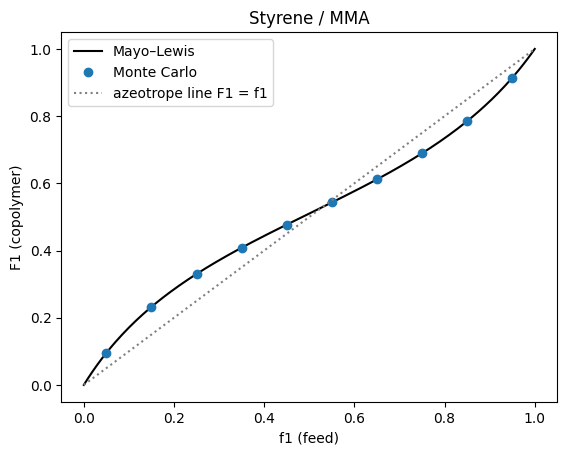

In [13]:
#@title Plot Monte Carlo vs. Mayo–Lewis
f = np.linspace(0, 1, 200); f2 = 1 - f
F_ml = (r1*f**2 + f*f2) / (r1*f**2 + 2*f*f2 + r2*f2**2)
plt.plot(f, F_ml, "k-", label="Mayo–Lewis")
plt.plot(f_values, F_mc, "o", label="Monte Carlo")
plt.plot([0, 1], [0, 1], ":", c="gray", label="azeotrope line F1 = f1")
plt.xlabel("f1 (feed)"); plt.ylabel("F1 (copolymer)"); plt.legend(); plt.title("Styrene / MMA"); plt.show()

## 4 · Seeing the sequences 👀
Same feed (`f1 = 0.5`), different chemistry. This function builds a sequence of `L` units with the terminal model:

In [14]:
def sequence(L, f1, r1, r2):
    Padd1 = prob_add_M1(f1, r1, r2)
    seq = [first_unit(f1)]
    while len(seq) < L:
        last = seq[-1]                     # [-1] = the last element
        if random.random() <= Padd1[last]:
            seq.append(1)
        else:
            seq.append(2)
    return seq

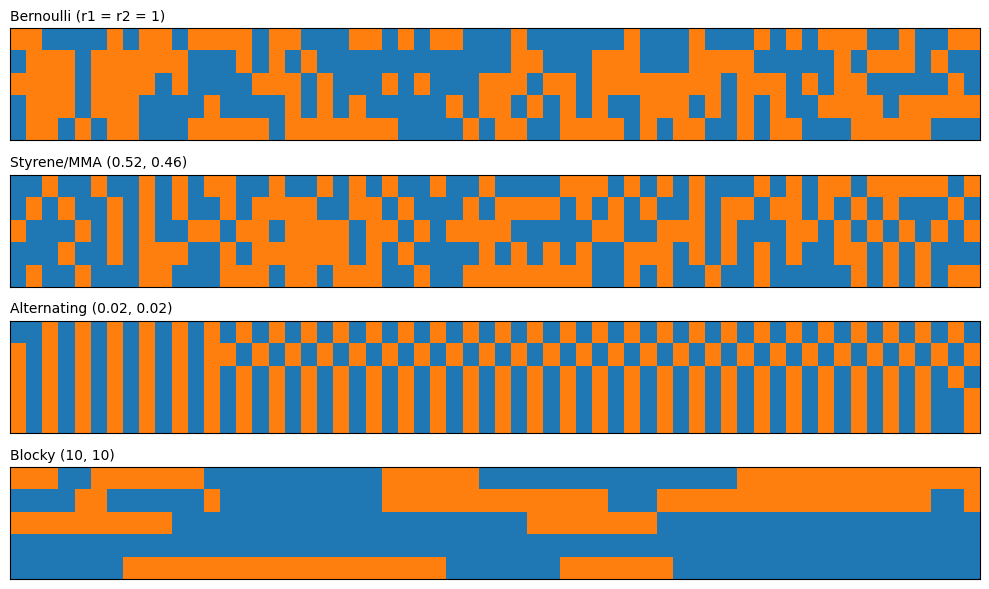

In [15]:
#@title Draw the sequences (orange = M1, blue = M2)
cases = {"Bernoulli (r1 = r2 = 1)": (1, 1), "Styrene/MMA (0.52, 0.46)": (0.52, 0.46),
         "Alternating (0.02, 0.02)": (0.02, 0.02), "Blocky (10, 10)": (10, 10)}
fig, axes = plt.subplots(len(cases), 1, figsize=(10, 6))
for ax, (title, (a, b)) in zip(axes, cases.items()):
    ax.imshow([sequence(60, 0.5, a, b) for _ in range(5)], cmap=ListedColormap(["tab:orange", "tab:blue"]), aspect="auto", vmin=1, vmax=2)
    ax.set_title(title, fontsize=10, loc="left"); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 5 · Bivariate map: chain length × composition
Look at both distributions at once: a 2D histogram, weighted by chain length (book Algorithm 3.5). Shorter chains (`P_p = 0.98`) make the composition spread easier to see.

In [16]:
D, N1 = run_terminal(100_000, 0.5, r1, r2, 0.98, Ptc)
F1 = N1 / D

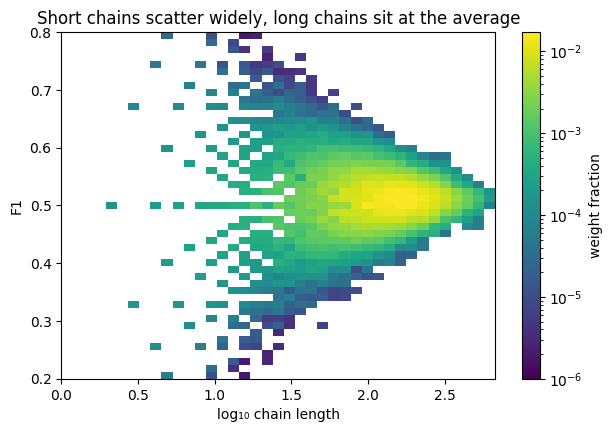

In [17]:
#@title Plot the bivariate map
n_edges = np.logspace(0, np.log10(D.max() + 1), 40); F_edges = np.linspace(0.2, 0.8, 50)
M, _, _ = np.histogram2d(D, F1, bins=[n_edges, F_edges], weights=D); M = M / M.sum()
fig, ax = plt.subplots(figsize=(7, 4.5))
pc = ax.pcolormesh(np.log10(n_edges), F_edges, M.T, cmap="viridis", norm=LogNorm(vmin=1e-6, vmax=M.max()))
fig.colorbar(pc, label="weight fraction"); ax.set_xlabel("log₁₀ chain length"); ax.set_ylabel("F1")
ax.set_title("Short chains scatter widely, long chains sit at the average"); plt.show()

## ✅ Recap
- A second `Rnd` per step decides **which** monomer adds → composition comes for free.
- **Bernoulli**: no memory. **Terminal model**: the probability depends on the last unit (`Padd1[last]`).
- The CCD narrows with chain length; the bivariate map shows both effects at once.
- Validate (Mayo–Lewis).

### 🧪 Try it yourself
1. Find the azeotrope of styrene/MMA, where F1 = f1. (Zoom into the validation plot.)
2. Use `r1, r2 = 10, 10` in the bivariate map. What happens to the composition spread?
3. Write a function that returns the longest run of M1 units in a sequence.

➡️ **Next: Notebook 4 — Long-chain branching** (the full styrene/MMA case study is Notebook 9)